# Momentum Bootstrap Heatmap

This notebook visualizes the reduced-CSI bootstrap certificate from `paper/sections/momentum.tex` for the two-scale white initialization

$$
\Sigma^{xx}_0=\sigma_{vu}^2 I_m,\qquad
\Xi_0=0,\qquad
\Sigma^{yy}_0=\sigma_{pq}^2 I_m.
$$

The convergence certificate holds when the bootstrap gap is negative:

$$
\mathfrak S_s(\gamma)-s<0.
$$


## Formula

For a deformation budget $s>0$,

$$
a_s=\sigma_{vu}^2 e^{-2s},\qquad
b_s=\sigma_{vu}^2 e^{2s},
$$

$$
\mathfrak K_s=4a_s\kappa,\qquad
\mathfrak L_s=4b_sL,
$$

$$
\rho_s=\mathfrak L_s+2\sqrt{2L\bar{\mathcal E}_0},
$$

$$
\varepsilon_s(\gamma)=
\min\left\{
\frac{1}{\sqrt{2\mathfrak L_s}},
\frac{\gamma}{2(\rho_s+2\gamma^2)}
\right\},
$$

$$
\lambda_s(\gamma)=
\frac23
\min\left\{
\frac34\varepsilon_s(\gamma)\mathfrak K_s,
\gamma
\right\},
$$

and

$$
\mathfrak S_s(\gamma)=
\frac4{\lambda_s(\gamma)}
\sqrt{\frac{3\bar{\mathcal E}_0}{2a_s}}.
$$


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.size": 6,
    "font.family": "serif",
    "axes.titlesize": 8,
    "axes.labelsize": 6,
    "legend.fontsize": 6,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "pgf.preamble": "\n".join([
        r"\usepackage{amsfonts}",  # Fixes the \mathbb error
        r"\usepackage{amssymb}",   # Optional: adds extra math symbols
    ])
})

Matplotlib is building the font cache; this may take a moment.


In [13]:
kappa = 1.0
L = 1.0
sigma_vus = np.logspace(0, 3, 25)
sigma_vu = float(sigma_vus[-1])
sigma_pq = 1
d_u = 3
d_v = 2
Delta0 = 1

gamma_min = 10.0
gamma_max = 10000.0
s_min = 1e-3
s_max = 2.0
gamma_count = 500
s_count = 500

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / "code" / "figures").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from inside the repository")
figure_dir = root / "code" / "figures"


In [14]:
def certificate_grid(
    gamma,
    s,
    *,
    kappa,
    L,
    sigma_vu,
    sigma_pq,
    d_u,
    d_v,
    Delta0,
):
    m = d_u + d_v
    Ebar0 = Delta0 + 0.5 * m * sigma_pq**2

    gamma_grid, s_grid = np.meshgrid(gamma, s)

    a_s = sigma_vu**2 * np.exp(-2.0 * s_grid)
    b_s = sigma_vu**2 * np.exp(2.0 * s_grid)

    kappa_phase_s = 4.0 * a_s * kappa
    L_phase_s = 4.0 * b_s * L
    rho_s = L_phase_s + 2.0 * np.sqrt(2.0 * L * Ebar0)
    
    epsilon_s = np.minimum(1.0 / np.sqrt(2.0 * L_phase_s), gamma_grid / (2.0 * (rho_s + 2.0 * gamma_grid**2)))
    lambda_s = (2.0 / 3.0) * np.minimum(0.75 * epsilon_s * kappa_phase_s, gamma_grid)

    S_s = (4.0 / lambda_s) * np.sqrt(3.0 * Ebar0 / (2.0 * a_s))
    gap = S_s - s_grid

    return gap, S_s, lambda_s

In [15]:
FIGURE_SIZE = (4.0, 3.0)
GRID_STYLE = {"which": "both", "color": "#E8E8E8", "linewidth": 0.8}


def new_figure(ax=None, *, figsize=FIGURE_SIZE):
    if ax is None:
        return plt.subplots(figsize=figsize, constrained_layout=True)
    return ax.figure, ax


def save_figure(fig, output, *, dpi=200, formats=("pdf", "pgf", "png")):
    if output is None:
        return

    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    for suffix in formats:
        fig.savefig(output.with_suffix(f".{suffix}"), dpi=dpi)


def finish_axes(
    ax,
    *,
    title=None,
    xlabel=r"$\gamma$",
    ylabel=None,
    xscale="log",
    yscale="log",
    grid=True,
    legend=None,
):
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xscale:
        ax.set_xscale(xscale)
    if yscale:
        ax.set_yscale(yscale)
    if grid:
        ax.grid(True, **GRID_STYLE)
    if legend:
        ax.legend(**legend)


def sigma_color_mapping(sigma_values, *, cmap_name="magma", cmap_range=(0.18, 0.92)):
    sigma_values = np.asarray(sigma_values, dtype=float)
    base_cmap = plt.get_cmap(cmap_name)
    cmap_lo, cmap_hi = cmap_range
    cmap = colors.LinearSegmentedColormap.from_list(
        f"{cmap_name}_{cmap_lo:g}_{cmap_hi:g}",
        base_cmap(np.linspace(cmap_lo, cmap_hi, 256)),
    )
    norm = colors.LogNorm(vmin=float(np.min(sigma_values)), vmax=float(np.max(sigma_values)))
    return cmap, norm


def sigma_color(sigma_value, cmap, norm):
    return cmap(norm(float(sigma_value)))


def add_sigma_colorbar(fig, ax, cmap, norm, *, label=r"$\sigma_{vu}$"):
    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array([])
    cbar = fig.colorbar(mappable, ax=ax)
    cbar.set_label(label)
    return cbar


def add_unique_legend_handle(ax, handle, *, loc="best", fontsize=None):
    legend = ax.get_legend()
    if legend is None:
        existing_handles, existing_labels = ax.get_legend_handles_labels()
    else:
        existing_handles = list(getattr(legend, "legend_handles", []))
        existing_labels = [text.get_text() for text in legend.get_texts()]

    label = handle.get_label()
    if label not in existing_labels:
        ax.legend(handles=[*existing_handles, handle], loc=loc, fontsize=fontsize)


def terminal_certified_point(gamma_values, lambda_values):
    finite = np.isfinite(lambda_values) & (lambda_values > 0.0)
    if not np.any(finite):
        return None

    last = np.flatnonzero(finite)[-1]
    if last == len(gamma_values) - 1:
        return None

    return float(gamma_values[last]), float(lambda_values[last])


def gap_colormap(gap):
    gap_min = float(np.nanmin(gap))
    gap_max = float(np.nanmax(gap))
    abs_hi = float(np.nanpercentile(np.abs(gap), 98))
    gap_plot = gap

    if gap_min < 0.0 < gap_max:
        norm = colors.SymLogNorm(
            linthresh=1.0,
            vmin=-abs_hi,
            vmax=abs_hi,
            base=10.0,
        )
        cmap = "coolwarm"
        colorbar_label = r"$\mathfrak{S}_s(\gamma)-s$"
    elif gap_min > 0.0:
        gap_hi = float(np.nanpercentile(gap, 98))
        norm = colors.LogNorm(vmin=gap_min, vmax=gap_hi)
        cmap = "magma"
        colorbar_label = r"$\mathfrak{S}_s(\gamma)-s$"
    else:
        gap_hi = float(np.nanpercentile(gap, 98))
        norm = colors.LogNorm(vmin=max(-gap_hi, 1e-12), vmax=max(-gap_min, 1e-12))
        cmap = "viridis_r"
        gap_plot = -gap
        colorbar_label = r"$s-\mathfrak{S}_s(\gamma)$"

    return gap_plot, cmap, norm, colorbar_label, gap_min, gap_max


def plot_gap(
    gamma,
    s,
    gap,
    *,
    ax=None,
    show_heatmap=True,
    show_contour=True,
    contour_color="black",
    contour_label=None,
    add_colorbar=True,
    title=None,
    output=None,
):
    gap_plot, cmap, norm, colorbar_label, gap_min, gap_max = gap_colormap(gap)
    fig, ax = new_figure(ax)
    artists = {}
    gamma_grid, s_grid = np.meshgrid(gamma, s)

    if show_heatmap:
        image = ax.pcolormesh(
            gamma_grid,
            s_grid,
            gap_plot,
            cmap=cmap,
            norm=norm,
            shading="auto",
            rasterized=True,
        )
        artists["heatmap"] = image
        if add_colorbar:
            cbar = fig.colorbar(image, ax=ax)
            cbar.set_label(colorbar_label)
            artists["colorbar"] = cbar

    if show_contour and gap_min <= 0.0 <= gap_max:
        contour = ax.contour(
            gamma,
            s,
            gap,
            levels=[0.0],
            colors=[contour_color],
            linewidths=1.25,
        )
        artists["contour"] = contour
        if contour_label is not None:
            artists["legend_handle"] = Line2D(
                [0],
                [0],
                color=contour_color,
                linewidth=1.25,
                label=contour_label,
            )
        elif show_heatmap:
            artists["legend_handle"] = Line2D(
                [0],
                [0],
                color=contour_color,
                linewidth=1.25,
                label=r"$\mathfrak{S}_s(\gamma)-s=0$",
            )

    legend_handle = artists.get("legend_handle")
    if legend_handle is not None:
        add_unique_legend_handle(
            ax,
            legend_handle,
            loc="upper right" if show_heatmap else "best",
            fontsize=None if show_heatmap else 7,
        )

    finish_axes(
        ax,
        title=title or r"Certified bootstrap gap $\mathfrak{S}_s(\gamma)-s$",
        xlabel=r"$\gamma$",
        ylabel=r"$s$",
        grid=False,
    )
    save_figure(fig, output)

    return fig, ax, artists


In [16]:
gamma = np.geomspace(gamma_min, gamma_max, gamma_count)
s = np.geomspace(s_min, s_max, s_count)

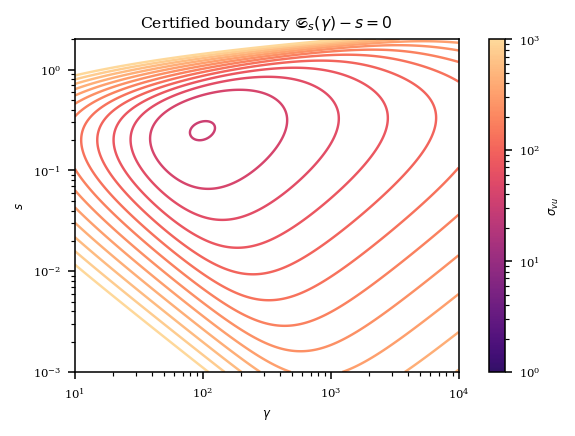

In [17]:
fig, ax = new_figure(figsize=(2.2, 1.65))
cmap, sigma_norm = sigma_color_mapping(sigma_vus)

for sigma_vu_value in sigma_vus:
    gap, S_s, lambda_s = certificate_grid(
        gamma,
        s,
        kappa=kappa,
        L=L,
        sigma_vu=sigma_vu_value,
        sigma_pq=sigma_pq,
        d_u=d_u,
        d_v=d_v,
        Delta0=Delta0,
    )
    plot_gap(
        gamma,
        s,
        gap,
        ax=ax,
        show_heatmap=False,
        show_contour=True,
        contour_color=sigma_color(sigma_vu_value, cmap, sigma_norm),
        add_colorbar=False,
        title=r"Certified boundary $\mathfrak{G}_s(\gamma)=0$",
    )

add_sigma_colorbar(fig, ax, cmap, sigma_norm)
save_figure(fig, Path(figure_dir / "momentum_bootstrap_heatmap_notebook"))

## Approximate First Admissible Budget

For each fixed $\gamma$, the first negative grid point approximates

$$
s_{\mathrm{cert}}(\gamma)=\inf\{s>0:\mathfrak S_s(\gamma)-s<0\}.
$$

For the large-position-scale limit with fixed $\sigma_{pq}$,

$$
s_{\mathrm{cert}}(\gamma)
\sim
\frac{16L}{\kappa\gamma\sigma_{vu}}
\sqrt{\frac{3\overline{\mathcal E}_0}{2}}.
$$

The corresponding leading asymptotic expansion of the certified rate is

$$
\lambda_{s_{\mathrm{cert}}}(\gamma)
\sim
\frac{\kappa\gamma}{4L}
-
\frac{16}{\sigma_{vu}}
\sqrt{\frac{3\overline{\mathcal E}_0}{2}}.
$$


In [18]:
def first_admissible_s(gamma_values, s_grid, gap_grid):
    rows = []
    for col, gamma_value in enumerate(gamma_values):
        negative = np.flatnonzero(gap_grid[:, col] < 0)
        if len(negative) == 0:
            rows.append((gamma_value, np.nan, np.nan))
        else:
            i = int(negative[0])
            rows.append((gamma_value, s_grid[i], gap_grid[i, col]))
    return rows


def first_admissible_values(gamma_values, s_grid, gap_grid, value_grid):
    rows = []
    for col, gamma_value in enumerate(gamma_values):
        negative = np.flatnonzero(gap_grid[:, col] < 0)
        if len(negative) == 0:
            rows.append((gamma_value, np.nan, np.nan, np.nan))
        else:
            i = int(negative[0])
            rows.append((gamma_value, s_grid[i], gap_grid[i, col], value_grid[i, col]))
    return rows


def asymptotic_s_cert(gamma_values, *, kappa, L, sigma_vu, sigma_pq, d_u, d_v, Delta0):
    m = d_u + d_v
    Ebar0 = Delta0 + 0.5 * m * sigma_pq**2
    gamma_values = np.asarray(gamma_values, dtype=float)
    return (
        16.0
        * L
        / (kappa * gamma_values * sigma_vu)
        * np.sqrt(3.0 * Ebar0 / 2.0)
    )


def asymptotic_lambda_s_cert(gamma_values, *, kappa, L, sigma_vu, sigma_pq, d_u, d_v, Delta0):
    m = d_u + d_v
    Ebar0 = Delta0 + 0.5 * m * sigma_pq**2
    gamma_values = np.asarray(gamma_values, dtype=float)
    return (
        kappa * gamma_values / (4.0 * L)
        - 16.0 / sigma_vu * np.sqrt(3.0 * Ebar0 / 2.0)
    )


s_cert_all = []

for gamma_value, s_cert, gap_value in first_admissible_s(gamma, s, gap):
    # if np.isnan(s_cert):
    #     print(f"gamma={gamma_value:.3g}: no certified s on this grid")
    # else:
    #     print(f"gamma={gamma_value:.3g}: first admissible s≈{s_cert:.6g}, gap={gap_value:.3g}")
    s_cert_all.append(s_cert)

s_cert_all = np.asarray(s_cert_all, dtype=float)
s_cert_asymptotic = asymptotic_s_cert(
    gamma,
    kappa=kappa,
    L=L,
    sigma_vu=sigma_vu,
    sigma_pq=sigma_pq,
    d_u=d_u,
    d_v=d_v,
    Delta0=Delta0,
)

# Use a separate log-spaced grid for the comparison plots so the first admissible
# budget is not clipped by the heatmap grid's lower endpoint.
gamma_compare = np.geomspace(1e-1, gamma_max, gamma_count)
s_compare = np.geomspace(1e-6, s_max, 1200)
gap_compare, _, lambda_compare_grid = certificate_grid(
    gamma_compare,
    s_compare,
    kappa=kappa,
    L=L,
    sigma_vu=sigma_vu,
    sigma_pq=sigma_pq,
    d_u=d_u,
    d_v=d_v,
    Delta0=Delta0,
)
first_values_compare = first_admissible_values(
    gamma_compare,
    s_compare,
    gap_compare,
    lambda_compare_grid,
)
s_cert_compare = np.asarray([s_cert for _, s_cert, _, _ in first_values_compare], dtype=float)
lambda_cert_compare = np.asarray([rate for _, _, _, rate in first_values_compare], dtype=float)
s_cert_asymptotic_compare = asymptotic_s_cert(
    gamma_compare,
    kappa=kappa,
    L=L,
    sigma_vu=sigma_vu,
    sigma_pq=sigma_pq,
    d_u=d_u,
    d_v=d_v,
    Delta0=Delta0,
)
lambda_cert_asymptotic_compare = asymptotic_lambda_s_cert(
    gamma_compare,
    kappa=kappa,
    L=L,
    sigma_vu=sigma_vu,
    sigma_pq=sigma_pq,
    d_u=d_u,
    d_v=d_v,
    Delta0=Delta0,
)


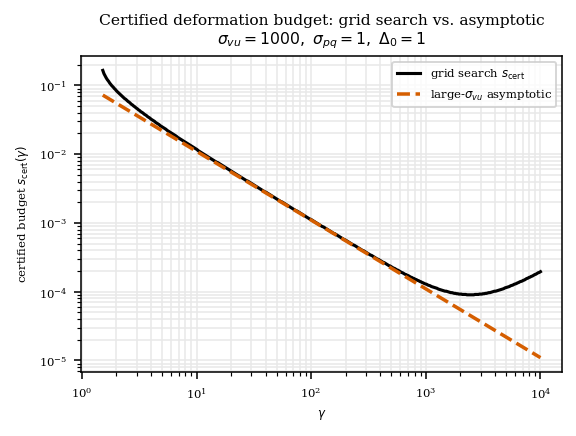

In [19]:
def plot_s_cert_comparison(gamma, s_cert_grid, s_cert_asymptotic, *, output=None):
    finite = np.isfinite(s_cert_grid) & np.isfinite(s_cert_asymptotic)

    fig, ax = new_figure()
    ax.plot(
        gamma[finite],
        s_cert_grid[finite],
        color="black",
        linewidth=1.6,
        label=r"grid search $s_{\mathrm{cert}}$",
    )
    ax.plot(
        gamma[finite],
        s_cert_asymptotic[finite],
        color="#D55E00",
        linewidth=1.8,
        linestyle="--",
        label=r"large-$\sigma_{vu}$ asymptotic",
    )

    finish_axes(
        ax,
        title=(
            r"Certified deformation budget: grid search vs. asymptotic"
            "\n"
            rf"$\sigma_{{vu}}={sigma_vu:g},\ \sigma_{{pq}}={sigma_pq:g},\ \Delta_0={Delta0}$"
        ),
        ylabel=r"certified budget $s_{\mathrm{cert}}(\gamma)$",
        legend={"loc": "best"},
    )
    save_figure(fig, output)

    return fig, ax


plot_s_cert_comparison(
    gamma_compare,
    s_cert_compare,
    s_cert_asymptotic_compare,
    output=Path(figure_dir / "momentum_bootstrap_scert_comparison.pdf"),
);


## Multiple Initial Position Scales

The next plot repeats the grid-search approximation of $s_{\mathrm{cert}}(\gamma)$ for several values of $\sigma_{vu}$ and compares each one with its corresponding large-$\sigma_{vu}$ asymptotic curve.  The $s$-grid starts lower than in the heatmap so that the larger scales are not clipped at small certified budgets.


In [24]:
sigma_values_s_cert = np.asarray([100.0, 1000.0, 10000.0])
gamma_multi = np.geomspace(gamma_min, gamma_max, gamma_count)
s_multi = np.unique(
    np.concatenate([
        np.geomspace(1e-10, s_max, 1800),
        np.linspace(0.02, 1.2, 800),
    ])
)


def certified_values_for_sigma(sigma_value):
    gap_sigma, _, lambda_sigma = certificate_grid(
        gamma_multi,
        s_multi,
        kappa=kappa,
        L=L,
        sigma_vu=sigma_value,
        sigma_pq=sigma_pq,
        d_u=d_u,
        d_v=d_v,
        Delta0=Delta0,
    )
    first_values = first_admissible_values(gamma_multi, s_multi, gap_sigma, lambda_sigma)
    s_cert = np.asarray([s_value for _, s_value, _, _ in first_values], dtype=float)
    lambda_cert = np.asarray([rate for _, _, _, rate in first_values], dtype=float)
    return s_cert, lambda_cert


certified_multi = {
    float(sigma_value): certified_values_for_sigma(float(sigma_value))
    for sigma_value in sigma_values_s_cert
}
s_cert_multi = {
    sigma_value: values[0]
    for sigma_value, values in certified_multi.items()
}
lambda_cert_multi = {
    sigma_value: values[1]
    for sigma_value, values in certified_multi.items()
}
s_cert_asymptotic_multi = {
    float(sigma_value): asymptotic_s_cert(
        gamma_multi,
        kappa=kappa,
        L=L,
        sigma_vu=float(sigma_value),
        sigma_pq=sigma_pq,
        d_u=d_u,
        d_v=d_v,
        Delta0=Delta0,
    )
    for sigma_value in sigma_values_s_cert
}
lambda_cert_asymptotic_multi = {
    float(sigma_value): asymptotic_lambda_s_cert(
        gamma_multi,
        kappa=kappa,
        L=L,
        sigma_vu=float(sigma_value),
        sigma_pq=sigma_pq,
        d_u=d_u,
        d_v=d_v,
        Delta0=Delta0,
    )
    for sigma_value in sigma_values_s_cert
}

for sigma_value in sigma_values_s_cert:
    sigma_value = float(sigma_value)
    finite = np.isfinite(s_cert_multi[sigma_value])
    if np.any(finite):
        print(
            rf"sigma_vu={sigma_value:g}: {np.count_nonzero(finite)} certified gamma values; "
            rf"range [{gamma_multi[finite][0]:.4g}, {gamma_multi[finite][-1]:.4g}]"
        )
    else:
        print(rf"sigma_vu={sigma_value:g}: no certified gamma values on this grid")


sigma_vu=100: 440 certified gamma values; range [15.15, 6601]
sigma_vu=1000: 500 certified gamma values; range [10, 1e+04]
sigma_vu=10000: 500 certified gamma values; range [10, 1e+04]


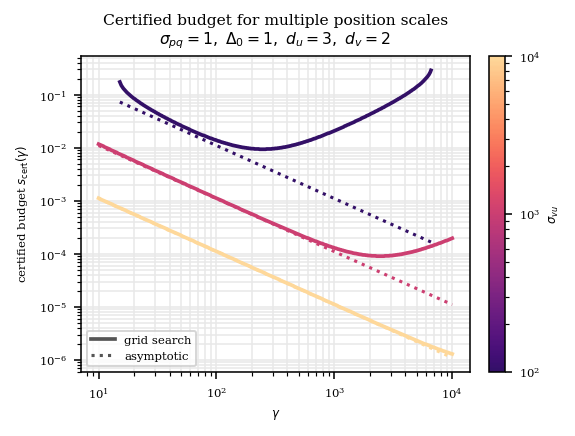

In [25]:
def plot_s_cert_multi_sigma(gamma, s_cert_by_sigma, asymptotic_by_sigma, *, output=None):
    fig, ax = new_figure()
    cmap, sigma_norm = sigma_color_mapping(sigma_values_s_cert)

    for sigma_value in sigma_values_s_cert:
        sigma_value = float(sigma_value)
        s_cert_grid = s_cert_by_sigma[sigma_value]
        s_cert_asymptotic = asymptotic_by_sigma[sigma_value]
        finite = np.isfinite(s_cert_grid) & np.isfinite(s_cert_asymptotic)
        if not np.any(finite):
            continue

        color = sigma_color(sigma_value, cmap, sigma_norm)
        ax.plot(
            gamma[finite],
            s_cert_grid[finite],
            color=color,
            linewidth=1.9,
        )
        ax.plot(
            gamma[finite],
            s_cert_asymptotic[finite],
            color=color,
            linewidth=1.6,
            linestyle=":",
        )

    ax.legend(
        handles=[
            Line2D([0], [0], color="#555555", linewidth=1.9, label="grid search"),
            Line2D([0], [0], color="#555555", linewidth=1.6, linestyle=":", label="asymptotic"),
        ],
        loc="best",
        fontsize=6,
    )
    add_sigma_colorbar(fig, ax, cmap, sigma_norm)
    finish_axes(
        ax,
        title=(
            r"Certified budget for multiple position scales"
            "\n"
            rf"$\sigma_{{pq}}={sigma_pq:g},\ \Delta_0={Delta0:g},\ d_u={d_u},\ d_v={d_v}$"
        ),
        ylabel=r"certified budget $s_{\mathrm{cert}}(\gamma)$",
    )
    save_figure(fig, output)

    return fig, ax


plot_s_cert_multi_sigma(
    gamma_multi,
    s_cert_multi,
    s_cert_asymptotic_multi,
    output=Path(figure_dir / "momentum_bootstrap_scert_multi_sigma.pdf"),
);


## Certified Rate Across Initial Position Scales

Using the same grid-search certificate, the next plot records the certified rate $\lambda_{s_{\mathrm{cert}}}(\gamma)$ at the first admissible budget for five logarithmically spaced values of $\sigma_{vu}$.  The asymptotic curves are visually indistinguishable on this scale, so the plot shows only the limiting large-$\sigma_{vu}$ rate as a single dotted black line.


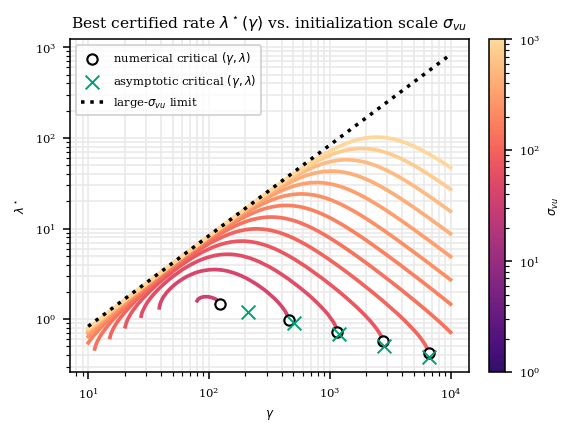

In [26]:
sigma_values_lambda_cert = np.geomspace(1.0, 1000.0, 25)
lambda_cert_rate_multi = {
    float(sigma_value): certified_values_for_sigma(float(sigma_value))[1]
    for sigma_value in sigma_values_lambda_cert
}


def limiting_lambda_cert_asymptotic(gamma, *, kappa=kappa, L=L, d_u=d_u, d_v=d_v):
    return kappa * gamma / (4.0 * L)


def asymptotic_gamma_max(sigma, *, kappa=kappa, sigma_pq=sigma_pq, d_u=d_u, d_v=d_v, Delta0=Delta0):
    m = d_u + d_v
    Ebar0 = Delta0 + 0.5 * m * sigma_pq**2
    return kappa * sigma**3 / (24.0 * np.e * np.sqrt(3.0 * Ebar0 / 2.0))


def asymptotic_lambda_opt(gamma, sigma, *, kappa=kappa):
    return kappa * sigma**2 * np.exp(-2.0 / 3.0) / (2.0 * gamma)


def asymptotic_critical_point(
    sigma,
    *,
    kappa=kappa,
    L=L,
    sigma_pq=sigma_pq,
    d_u=d_u,
    d_v=d_v,
    Delta0=Delta0,
):
    gamma_theory = asymptotic_gamma_max(
        sigma,
        kappa=kappa,
        sigma_pq=sigma_pq,
        d_u=d_u,
        d_v=d_v,
        Delta0=Delta0,
    )
    lambda_theory = asymptotic_lambda_opt(
        gamma_theory,
        sigma,
        kappa=kappa,
    )
    return gamma_theory, lambda_theory


def plot_lambda_cert_multi_sigma(gamma, lambda_by_sigma, *, output=None):
    fig, ax = new_figure()
    cmap, sigma_norm = sigma_color_mapping(sigma_values_lambda_cert)
    critical_points = []
    critical_points_theory = []

    for sigma_value in sigma_values_lambda_cert:
        sigma_value = float(sigma_value)
        lambda_grid = lambda_by_sigma[sigma_value]
        finite = np.isfinite(lambda_grid) & (lambda_grid > 0.0)
        if not np.any(finite):
            continue

        ax.plot(
            gamma[finite],
            lambda_grid[finite],
            color=sigma_color(sigma_value, cmap, sigma_norm),
            linewidth=1.9,
        )

        critical_point = terminal_certified_point(gamma, lambda_grid)
        critical_point_theory = asymptotic_critical_point(sigma_value)
        if critical_point is not None:
            critical_points.append(critical_point)
            critical_points_theory.append(critical_point_theory)

    if critical_points:
        critical_gamma, critical_lambda = np.asarray(critical_points, dtype=float).T
        ax.scatter(
            critical_gamma,
            critical_lambda,
            marker="o",
            color="w",
            edgecolor='k',
            s=28,
            linewidths=1.1,
            label=r"numerical critical $(\gamma, \lambda)$",
            zorder=5,
        )
        critical_gamma_theory, critical_lambda_theory = np.asarray(critical_points_theory, dtype=float).T
        ax.scatter(
            critical_gamma_theory,
            critical_lambda_theory,
            marker="x",
            color="#009E73",
            s=50,
            linewidths=1.0,
            label=r"asymptotic critical $(\gamma, \lambda)$",
            zorder=6,
        )

    lambda_limit = limiting_lambda_cert_asymptotic(gamma)
    finite_limit = np.isfinite(lambda_limit) & (lambda_limit > 0.0)
    ax.plot(
        gamma[finite_limit],
        lambda_limit[finite_limit],
        color="black",
        linewidth=1.8,
        linestyle=":",
        label=r"large-$\sigma_{vu}$ limit",
    )

    add_sigma_colorbar(fig, ax, cmap, sigma_norm)
    finish_axes(
        ax,
        title=(
            r"Boundary rate $\lambda_{\mathrm{cert}}(\gamma)$ vs. damping $\gamma$"
        ),
        ylabel=r"$\lambda_{\mathrm{cert}}$",
        legend={"loc": "best", "fontsize": 6},
    )
    save_figure(fig, output)

    return fig, ax


plot_lambda_cert_multi_sigma(
    gamma_multi,
    lambda_cert_rate_multi,
    output=Path(figure_dir / "momentum_bootstrap_lambda_multi_sigma"),
);


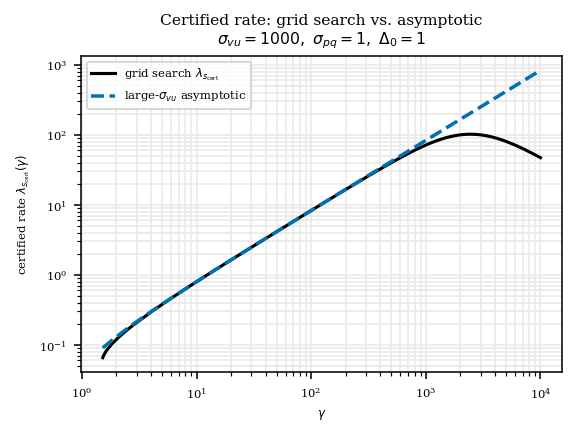

In [27]:
def plot_lambda_cert_comparison(gamma, lambda_grid, lambda_asymptotic, *, output=None):
    finite = np.isfinite(lambda_grid) & (lambda_grid > 0.0)
    finite &= np.isfinite(lambda_asymptotic) & (lambda_asymptotic > 0.0)

    fig, ax = new_figure()
    ax.plot(
        gamma[finite],
        lambda_grid[finite],
        color="black",
        linewidth=1.6,
        label=r"grid search $\lambda_{s_{\mathrm{cert}}}$",
    )
    ax.plot(
        gamma[finite],
        lambda_asymptotic[finite],
        color="#0072B2",
        linewidth=1.8,
        linestyle="--",
        label=r"large-$\sigma_{vu}$ asymptotic",
    )

    finish_axes(
        ax,
        title=(
            r"Certified rate: grid search vs. asymptotic"
            "\n"
            rf"$\sigma_{{vu}}={sigma_vu:g},\ \sigma_{{pq}}={sigma_pq:g},\ \Delta_0={Delta0}$"
        ),
        ylabel=r"certified rate $\lambda_{s_{\mathrm{cert}}}(\gamma)$",
        legend={"loc": "best"},
    )
    save_figure(fig, output)

    return fig, ax


plot_lambda_cert_comparison(
    gamma_compare,
    lambda_cert_compare,
    lambda_cert_asymptotic_compare,
    output=Path(figure_dir / "momentum_bootstrap_lambda_comparison.pdf"),
);
